## Szkieletyzacja (skeletonization)

Szkieletyzacja polega na stopniowym usuwaniu pikseli z krawędzi obiektu, aż pozostanie jego szkielet — cienka linia biegnąca wzdłuż „środka” obiektu.
Szkielet zachowuje:
* kształt (ogólny zarys),
* topologię (połączenia między częściami),
* długość i układ rozgałęzień.

Piksele z brzegu obiektu są usuwane iteracyjnie, ale tylko wtedy, gdy:
* nie naruszają spójności obiektu,
* nie rozdzielają go na kilka części.

## Pocienianie (thinning)

Pocienianie to proces redukcji szerokości obiektu binarnego do linii o grubości jednego piksela, **bez koniecznego zachowania osi symetrii** jak w szkieletyzacji.
Działa poprzez stopniowe „ścienianie” kształtu z krawędzi, aż obiekt stanie się maksymalnie cienki.

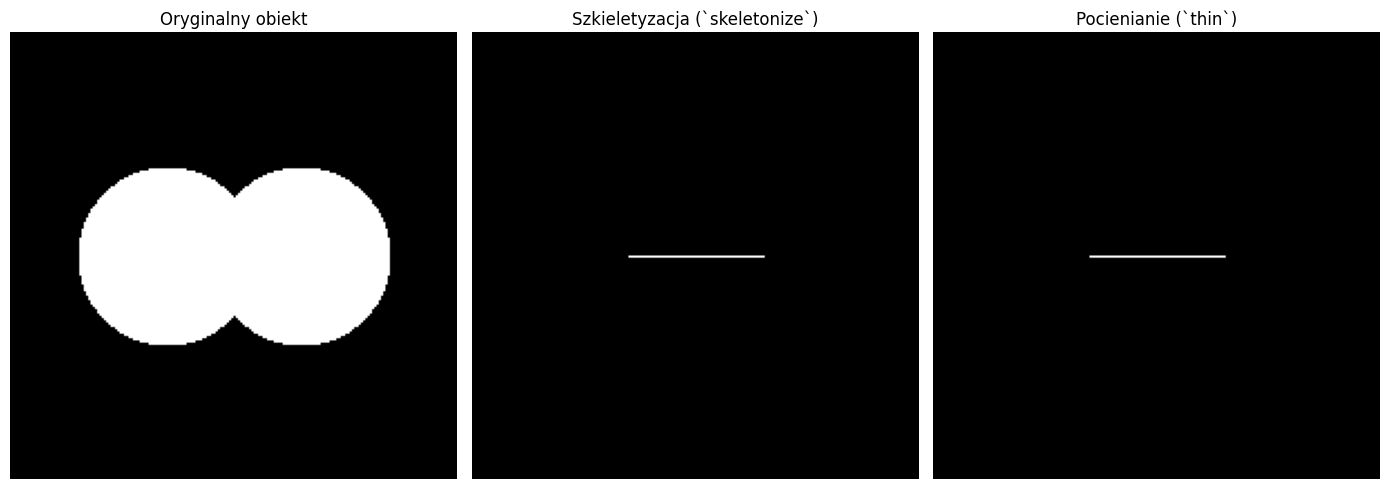

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from skimage.morphology import skeletonize, thin
from skimage.draw import disk
from skimage.util import invert

# Utwórz prosty obiekt (np. dwa połączone okręgi)
image = np.zeros((200, 200), dtype=bool)
rr, cc = disk((100, 70), 40)
image[rr, cc] = 1
rr, cc = disk((100, 130), 40)
image[rr, cc] = 1

# Szkieletyzacja i pocienianie
skeleton = skeletonize(image)
thinned = thin(image)

# Wizualizacja
fig, ax = plt.subplots(1, 3, figsize=(14, 5))
ax[0].imshow(image, cmap='gray')
ax[0].set_title("Oryginalny obiekt")

ax[1].imshow(skeleton, cmap='gray')
ax[1].set_title("Szkieletyzacja (`skeletonize`)")

ax[2].imshow(thinned, cmap='gray')
ax[2].set_title("Pocienianie (`thin`)")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()

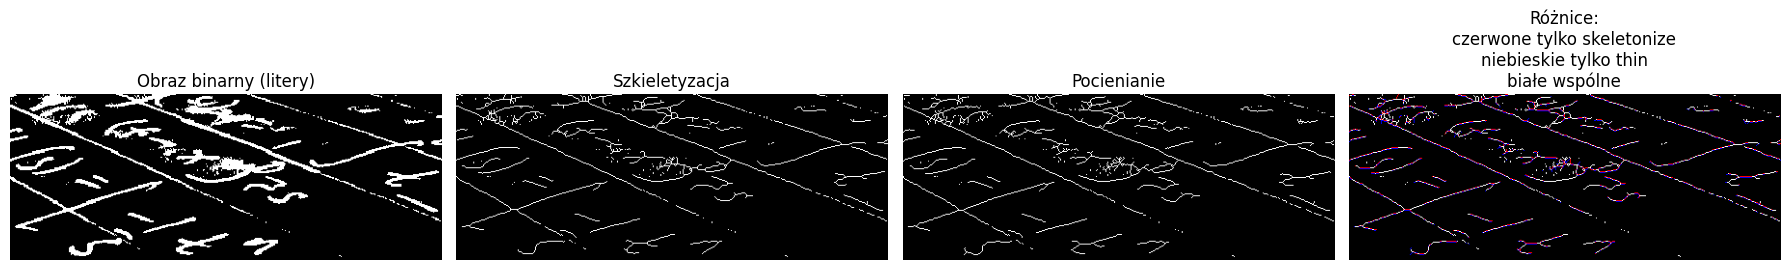

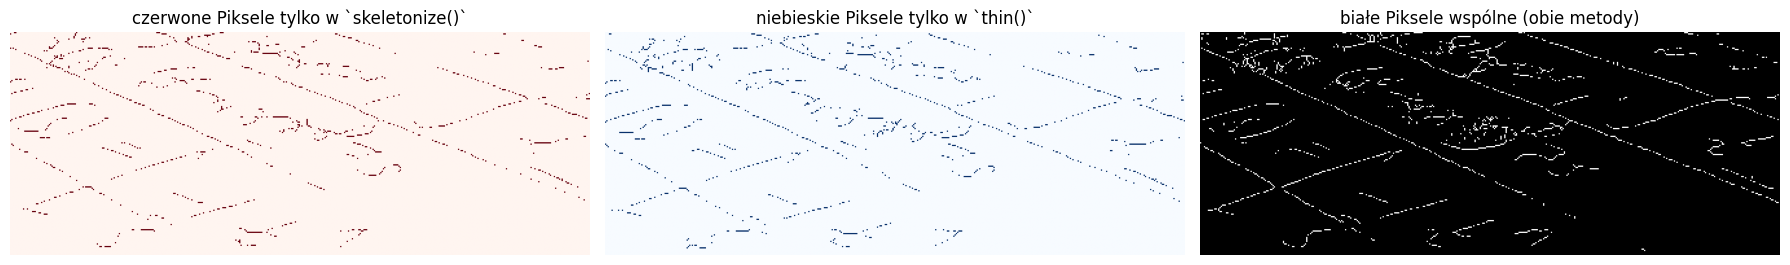

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color
from skimage.filters import threshold_otsu
from skimage.morphology import skeletonize, thin

# Wczytaj obraz tekstu
img = data.text()

# Sprawdź czy RGB czy już 2D
if img.ndim == 3:
    gray = color.rgb2gray(img)
else:
    gray = img.astype(np.float64)
    if gray.max() > 1.0:
        gray /= gray.max()

# Binarizacja
th = threshold_otsu(gray)
binary = gray < th
binary = binary.astype(bool)

# Szkieletyzacja i pocienianie
skel = skeletonize(binary)
thin_img = thin(binary)

# Oblicz różnice
only_skel = np.logical_and(skel, np.logical_not(thin_img))   # czerwone
only_thin = np.logical_and(thin_img, np.logical_not(skel))   # niebieskie
both = np.logical_and(skel, thin_img)                        # wspólne (białe)

# Utwórz kolorowy obraz różnic
diff_rgb = np.zeros((*binary.shape, 3))
diff_rgb[..., 0] = only_skel      # red channel
diff_rgb[..., 2] = only_thin      # blue channel
diff_rgb[..., 0:3] += both[..., None]  # dodaj wspólne (biały)

# --- Główne porównanie (4 obrazy) ---
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
ax[0].imshow(binary, cmap='gray')
ax[0].set_title("Obraz binarny (litery)")

ax[1].imshow(skel, cmap='gray')
ax[1].set_title("Szkieletyzacja")

ax[2].imshow(thin_img, cmap='gray')
ax[2].set_title("Pocienianie")

ax[3].imshow(diff_rgb)
ax[3].set_title("Różnice:\nczerwone tylko skeletonize\nniebieskie tylko thin\nbiałe wspólne")

for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()

# --- Dodatkowe trzy obrazy osobno ---
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

ax[0].imshow(only_skel, cmap='Reds')
ax[0].set_title("czerwone Piksele tylko w `skeletonize()`")

ax[1].imshow(only_thin, cmap='Blues')
ax[1].set_title("niebieskie Piksele tylko w `thin()`")

ax[2].imshow(both, cmap='gray')
ax[2].set_title("białe Piksele wspólne (obie metody)")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()

* Czerwony - Piksele obecne tylko w skeletonize - Ta metoda zostawia nieco „grubsze” fragmenty i rozgałęzienia.
* Niebieski	- Piksele obecne tylko w thin	Pocienianie usuwa więcej pikseli – daje cieńszy, jednolity szkielet.
* Biały	- Piksele wspólne	To „rdzeń” kształtu – wspólna oś uznana przez obie metody.

## Przycinanie (z ang. Pruning) to proces usuwania krótkich, nieistotnych gałązek ze szkieletu obiektu binarnego.
Celem tej operacji jest oczyszczenie szkieletu z drobnych odgałęzień, które powstały w wyniku:

* szumów w obrazie,
* niejednorodnego oświetlenia,
* nieidealnej segmentacji lub binarizacji.

Metody przycinania

* Iteracyjne usuwanie końcówek - najprostsza metoda: w każdej iteracji usuwa się piksele końcowe (z jednym sąsiadem). Po kilku iteracjach znikają krótkie odnogi, ale główny kształt zostaje zachowany.

* Pruning oparty na długości gałęzi. Wykrywa wszystkie gałęzie i mierzy ich długość (np. przez przeszukiwanie grafu). Usuwa tylko te, których długość < ustalonego progu (np. 10 pikseli).

* Pruning morfologiczny - Wykorzystuje operacje morfologiczne (np. hit-or-miss) do usuwania specyficznych wzorców końcówek.

C:\Users\user\AppData\Local\Temp\ipykernel_2448\2230044110.py:25: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  binary = remove_small_objects(binary, 64)


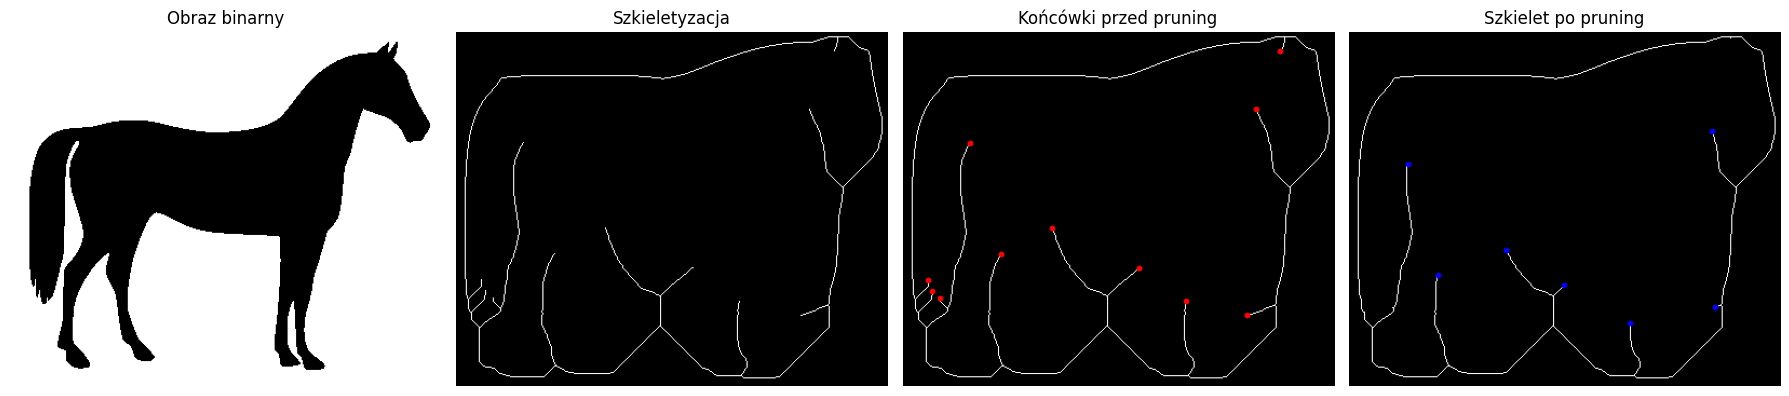

Piksele szkieletu (przed): 1823
Piksele szkieletu (po)   : 1624
Końcówki (przed)         : 11
Końcówki (po)            : 7


In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve
from skimage import data, color
from skimage.filters import threshold_otsu
from skimage.morphology import skeletonize, remove_small_objects

# --------- 0) Pomocnicze: bezpieczne przygotowanie obrazu binarnego ---------
def to_binary(img):
    """Zwraca obraz binarny (bool) niezależnie od formatu wejścia."""
    if img.dtype == bool and img.ndim == 2:
        return img
    if img.ndim == 3:   # RGB -> gray
        gray = color.rgb2gray(img)
    else:               # już 2D
        gray = img.astype(float)
        if gray.max() > 1.0:  # unormuj jeśli trzeba
            gray /= gray.max()
    th = threshold_otsu(gray)
    return (gray < th)  # ciemne obiekty = True

# Dane i binarizacja
img = data.horse()              # 2D (często bool)
binary = to_binary(img)
binary = remove_small_objects(binary, 64)

# Szkieletyzacja
skel = skeletonize(binary)

# Końcówki i pruning
def find_endpoints(skel_bool):
    """Zwraca maskę końcówek (pikseli z 1 sąsiadem w 8-sąsiedztwie)."""
    # 10 dla centrum, 1 dla sąsiadów -> 10 + 1 = 11 oznacza końcówkę
    kernel = np.array([[1,1,1],
                       [1,10,1],
                       [1,1,1]])
    conv = convolve(skel_bool.astype(np.uint8), kernel, mode='constant', cval=0)
    return conv == 11

def prune_skeleton(skel_bool, max_len=15):
    """
    Iteracyjnie usuwa końcówki do zadanej długości gałązki (max_len w pikselach).
    Każda iteracja odcina 1 piksel na końcu gałęzi.
    """
    pruned = skel_bool.copy()
    for _ in range(max_len):
        endpoints = find_endpoints(pruned)
        # zatrzymaj, gdy nie ma już krótkich końcówek
        if not endpoints.any():
            break
        pruned = np.logical_and(pruned, ~endpoints)
    return pruned

pruned = prune_skeleton(skel, max_len=20)

# Wizualizacja: oryginał, szkielet, końcówki, pruning
endpoints_before = find_endpoints(skel)
endpoints_after  = find_endpoints(pruned)

fig, ax = plt.subplots(1, 4, figsize=(18, 5))
ax[0].imshow(binary, cmap='gray'); ax[0].set_title("Obraz binarny"); ax[0].axis('off')
ax[1].imshow(skel, cmap='gray');   ax[1].set_title("Szkieletyzacja"); ax[1].axis('off')

# nałóż końcówki przed pruning (czerwone)
ax[2].imshow(skel, cmap='gray')
y, x = np.where(endpoints_before)
ax[2].scatter(x, y, s=10, c='r')
ax[2].set_title("Końcówki przed pruning"); ax[2].axis('off')

# szkielet po pruning + końcówki po (niebieskie)
ax[3].imshow(pruned, cmap='gray')
y2, x2 = np.where(endpoints_after)
ax[3].scatter(x2, y2, s=10, c='b')
ax[3].set_title("Szkielet po pruning"); ax[3].axis('off')

plt.tight_layout()
plt.show()

# Prosta statystyka
print("Piksele szkieletu (przed):", int(skel.sum()))
print("Piksele szkieletu (po)   :", int(pruned.sum()))
print("Końcówki (przed)         :", int(endpoints_before.sum()))
print("Końcówki (po)            :", int(endpoints_after.sum()))

# Zadanie 1. Analiza odcisków palców z wykorzystaniem szkieletyzacji

## Cel zadania
Celem jest przygotowanie obrazu odcisku palca, uzyskanie **jednopikselowego szkieletu linii papilarnych** i automatyczne wykrycie charakterystycznych punktów (**minucji**):
- **zakończeń linii** (ridge endings),
- **rozwidleń linii** (bifurcations).

### Etapy
1. Wczytanie obrazu w skali szarości.
2. Poprawa kontrastu (np. CLAHE).
3. Binaryzacja (Odsu, Sauvola).
4. Usunięcie drobnych zakłóceń (morfologia).
5. Szkieletyzacja.
6. Wykrywanie minucji metodą **Crossing Number**.
7. Wizualizacja i interpretacja wyników.

## Skąd pobrać obrazy odcisków palców?


*  NIST Special Database 302: https://www.nist.gov/itl/iad/btg/nist-special-database-302?utm_source=chatgpt.com
*  Tsinghua Simulated Fingerprint Database: https://ivg.au.tsinghua.edu.cn/dataset/TDFD.php


In [25]:
def display_image(images, titles=None, cmap='gray'):
    """
    Wyświetla maksymalnie trzy obrazy w każdym wierszu.
    
    Parametry:
    images : list
        Lista obrazów do wyświetlenia.
    titles : list, opcjonalnie
        Lista tytułów dla każdego obrazu. Jeśli None, nie wyświetla tytułów.
    cmap : str, opcjonalnie
        Kolor mapy do użycia przy wyświetlaniu obrazów (domyślnie 'gray').
    """
    n = len(images)
    if n == 0:
        return

    columns = min(3, n)
    rows = (n + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 5 * rows), squeeze=False)

    for i, image in enumerate(images):
        ax = axes[i // columns, i % columns]
        ax.imshow(image, cmap=cmap)
        if titles is not None:
            ax.set_title(titles[i])
        ax.axis('off')

    for i in range(n, rows * columns):
        axes[i // columns, i % columns].axis('off')

    plt.tight_layout()
    plt.show()

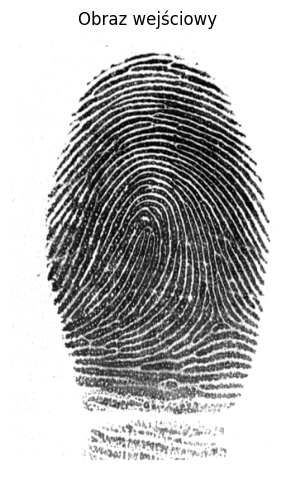

In [26]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import io, color, filters, morphology

def load_gray(path):
    img = io.imread(path)
    if img.ndim == 3:
        img = color.rgb2gray(img[..., :3])
    return img / img.max()

gray = load_gray("fingerprint_small.png")
display_image([gray], titles=["Obraz wejściowy"])


## 1. Przygotowanie obrazu i binaryzacja
1. **Filtr Gaussa** usuwa drobny szum, żeby CLAHE go nie wzmocniło.
2. **CLAHE** poprawia lokalny kontrast.
3. **Maska ROI**: mocno rozmyty obraz jest ciemny tam, gdzie jest odcisk, a jasny na tle. Progujemy go metodą Otsu i lekko zmniejszamy (erozja), żeby odciąć brzeg odcisku.
4. **Binaryzacja Sauvola** (próg lokalny) daje linie = `True`.
5. **Czyszczenie**: usuwamy małe obiekty i zalewamy małe dziurki (pory).


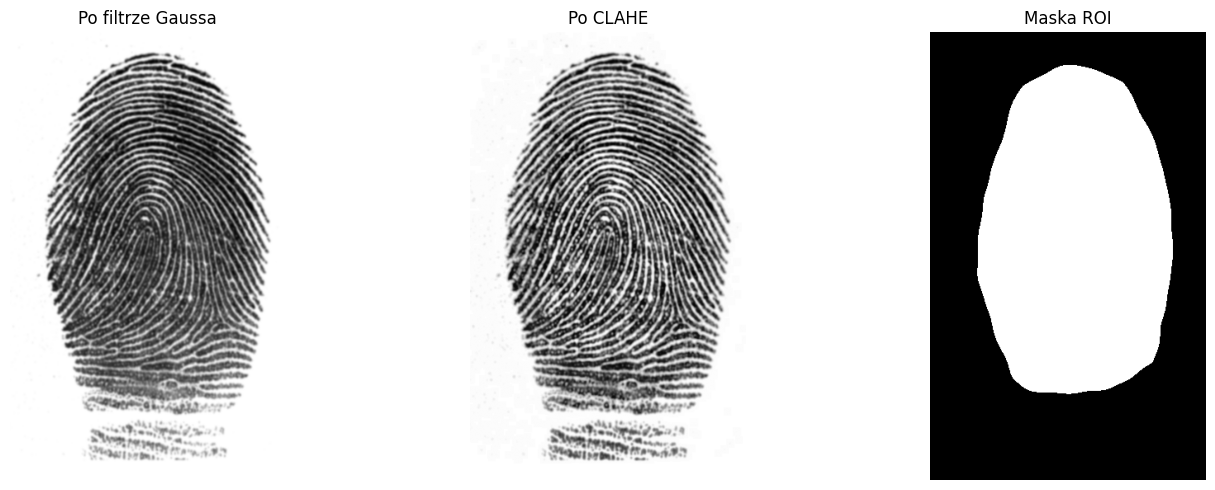

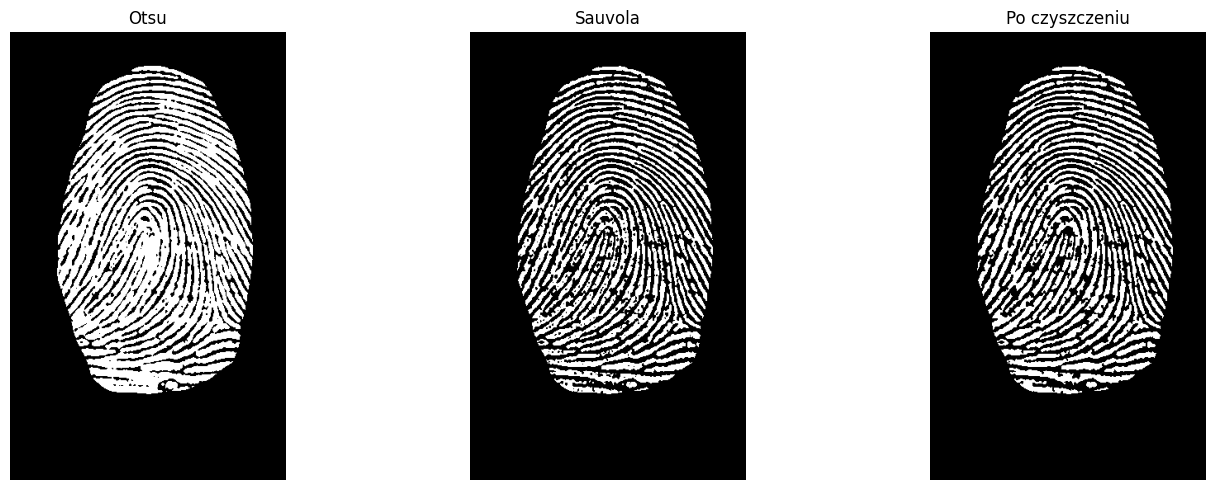

In [27]:
GAUSS_SIGMA = 1.0
SAUVOLA_WINDOW = 25
MIN_OBJECT_SIZE = 22

smooth = filters.gaussian(gray, sigma=GAUSS_SIGMA)
clahe_image = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply((smooth * 255).astype(np.uint8))

roi = filters.gaussian(gray, sigma=10) < filters.threshold_otsu(filters.gaussian(gray, sigma=10))
roi = ndi.binary_fill_holes(roi)
roi = ndi.binary_erosion(roi, iterations=10)

otsu_img = (clahe_image < filters.threshold_otsu(clahe_image)) & roi
bin_img = (clahe_image < filters.threshold_sauvola(clahe_image, window_size=SAUVOLA_WINDOW)) & roi

clean_img = morphology.remove_small_objects(bin_img, max_size=MIN_OBJECT_SIZE)
clean_img = morphology.remove_small_holes(clean_img, max_size=MIN_OBJECT_SIZE)

display_image([smooth, clahe_image, roi], titles=["Po filtrze Gaussa", "Po CLAHE", "Maska ROI"])
display_image([otsu_img, bin_img, clean_img], titles=["Otsu", "Sauvola", "Po czyszczeniu"])


## 2. Szkieletyzacja i przycinanie
Pruning: `PRUNE_LEN` razy obcinamy końcówki (piksele z jednym sąsiadem), potem tyle samo razy „odrastamy” po oryginalnym szkielecie. Krótkie gałązki znikają, długie linie wracają do pełnej długości.


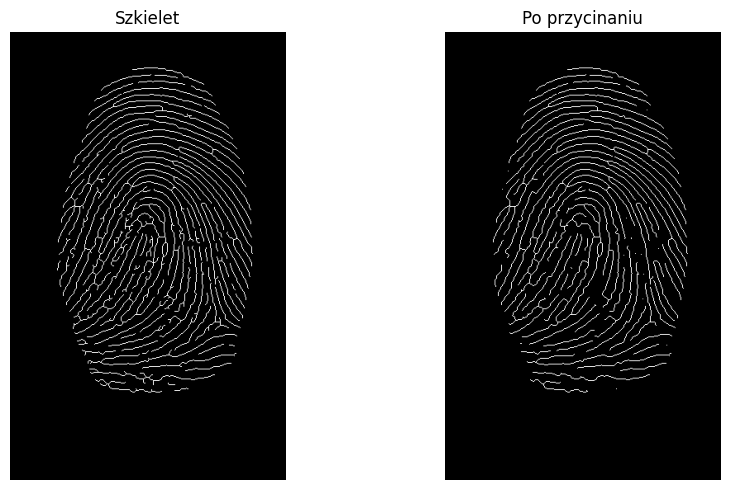

In [28]:
PRUNE_LEN = 12
K = np.array([[1, 1, 1], [1, 10, 1], [1, 1, 1]])   # wynik 11 = piksel szkieletu z 1 sąsiadem

def endpoints(sk):
    return ndi.convolve(sk.astype(int), K, mode='constant') == 11

def prune(skel, n=PRUNE_LEN):
    sk = skel.copy()
    for _ in range(n):
        sk &= ~endpoints(sk)
    grow = endpoints(sk)
    for _ in range(n):
        grow = ndi.binary_dilation(grow, np.ones((3, 3))) & skel & ~sk
        sk |= grow
    return morphology.skeletonize(sk)

skeleton = morphology.skeletonize(clean_img)
pruned = prune(skeleton)
display_image([skeleton, pruned], titles=["Szkielet", "Po przycinaniu"])


## 3. Wykrywanie minucji – Crossing Number

Dla każdego piksela szkieletu liczymy liczbę zmian wartości w cyklicznym otoczeniu 8 sąsiadów:

$$CN = \frac{1}{2}\sum_{i=1}^{8}|P_i-P_{i+1}|,\qquad P_9=P_1.$$

Interpretacja (dla poprawnie wyznaczonego, jednopikselowego szkieletu):
- `CN = 1` – zakończenie linii,
- `CN = 2` – punkt ciągłej linii,
- `CN = 3` – rozwidlenie.

Punkty wykryte przy brzegu obszaru zainteresowania często nie są rzeczywistymi minucjami. Dlatego wykluczamy je i grupujemy sąsiadujące wykrycia. Wynik jest **heurystyczny**, nie stanowi gotowego systemu identyfikacji biometrycznej.

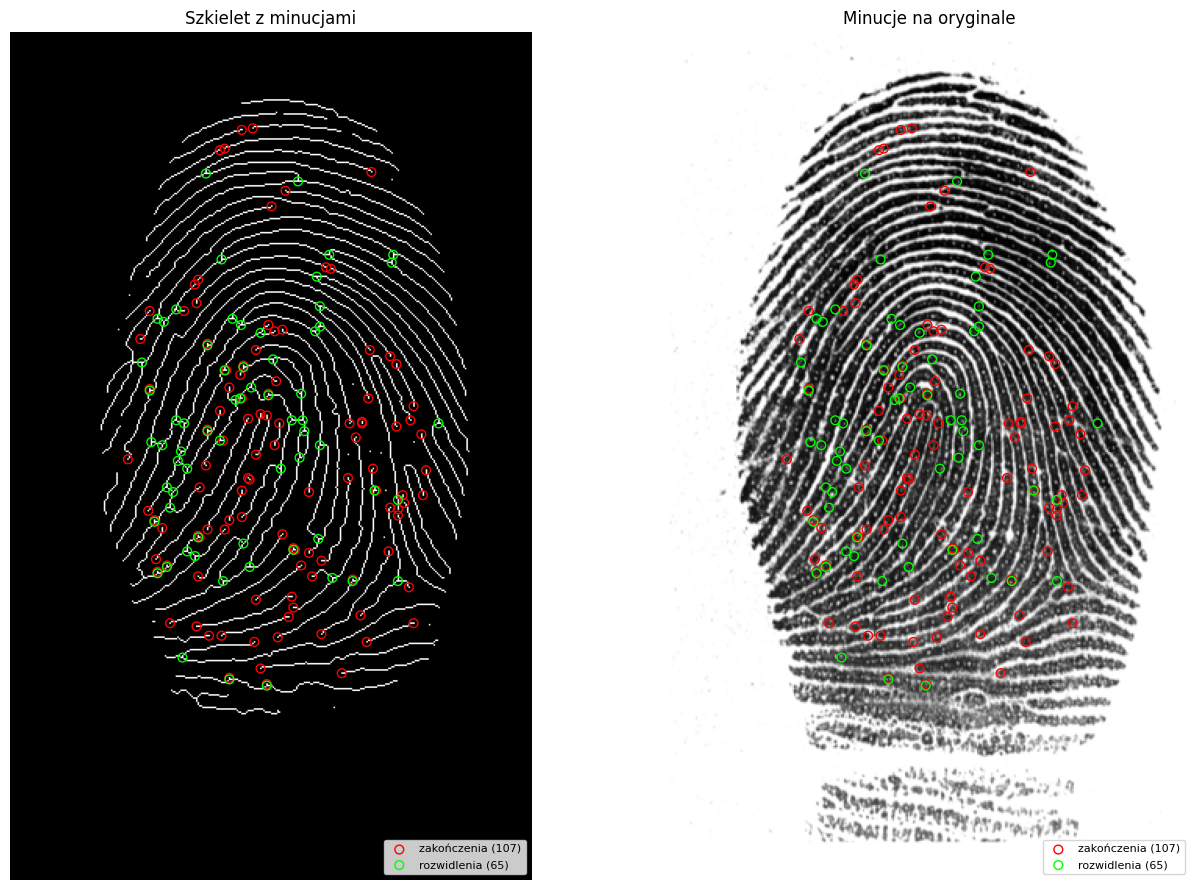

In [29]:
BORDER = 15   # minucje bliżej brzegu ROI niż 15 px odrzucamy

def crossing_number(sk):
    p = np.pad(sk.astype(int), 1)
    h, w = sk.shape
    # 8 sąsiadów po kolei dookoła piksela
    n = [p[1+dy:1+dy+h, 1+dx:1+dx+w] for dy, dx in [(-1,0),(-1,1),(0,1),(1,1),(1,0),(1,-1),(0,-1),(-1,-1)]]
    cn = sum(abs(n[i] - n[(i + 1) % 8]) for i in range(8)) // 2
    return cn * sk

def find_minutiae(sk, roi):
    cn = crossing_number(sk)
    inside = ndi.binary_erosion(roi, iterations=BORDER)
    ends = np.argwhere((cn == 1) & inside)
    lab, n = ndi.label((cn >= 3) & inside, structure=np.ones((3, 3)))   # sklejone piksele rozwidlenia = 1 punkt
    bifs = np.array(ndi.center_of_mass(lab > 0, lab, range(1, n + 1))).reshape(-1, 2)
    return ends, bifs

def show(ax, img, ends, bifs, title):
    ax.imshow(img, cmap='gray')
    ax.scatter(ends[:, 1], ends[:, 0], s=40, facecolors='none', edgecolors='red', label=f"zakończenia ({len(ends)})")
    ax.scatter(bifs[:, 1], bifs[:, 0], s=40, facecolors='none', edgecolors='lime', label=f"rozwidlenia ({len(bifs)})")
    ax.set_title(title); ax.axis('off'); ax.legend(loc='lower right', fontsize=8)

ends, bifs = find_minutiae(pruned, roi)
fig, ax = plt.subplots(1, 2, figsize=(14, 9))
show(ax[0], pruned, ends, bifs, "Szkielet z minucjami")
show(ax[1], gray, ends, bifs, "Minucje na oryginale")
plt.tight_layout(); plt.show()


## 4. Zadania do wykonania przez studentów

1. **Wykonaj cały algorytm** dla obrazu testowego i zapisz wizualizacje etapów (Obraz oryginalny, Obraz po poprawie kontrastu, Obraz po binaryzacji, Obraz po operacjach morfologicznych, Obraz po szkieletyzacji, Szkielet z zaznaczonymi zakończeniami, rozwidleniami linii, minucjami)
2. **Zmień parametr** `SAUVOLA_WINDOW` na 15, 25 i 41. Porównaj otrzymane szkielety i liczby minucji.
3. **Zmień** `MIN_OBJECT_SIZE` na 10, 22 i 50. Sprawdź, czy zmienia się liczba fałszywych zakończeń.
4. Wczytaj **inny obraz odcisku palca** i oceń jakość działania algorytmu.
5. Wskaż na obrazie co najmniej **dwa błędnie wykryte punkty** i wyjaśnij, skąd się wzięły (jeśli błędów nie ma, opisz mechanizm ich powstawania).



### Zadanie 1
Wszystkie etapy pokazane wyżej; zapisujemy je do katalogu `wyniki/`.


In [30]:
import os
os.makedirs("wyniki", exist_ok=True)
for name, img in [("1_oryginal", gray), ("2_kontrast", clahe_image), ("3_binaryzacja", bin_img),
                  ("4_morfologia", clean_img), ("5_szkielet", pruned)]:
    plt.imsave(f"wyniki/{name}.png", img, cmap='gray')

for name, e, b in [("6_zakonczenia", ends, bifs[:0]), ("7_rozwidlenia", ends[:0], bifs), ("8_minucje", ends, bifs)]:
    fig, ax = plt.subplots(figsize=(7, 10))
    show(ax, pruned, e, b, name)
    fig.savefig(f"wyniki/{name}.png", bbox_inches='tight'); plt.close(fig)
print(sorted(os.listdir("wyniki")))


['1_oryginal.png', '2_kontrast.png', '3_binaryzacja.png', '4_morfologia.png', '5_szkielet.png', '6_zakonczenia.png', '7_rozwidlenia.png', '8_minucje.png']


### Zadanie 2 i 3
Cały algorytm w jednej funkcji, żeby łatwo zmieniać parametry.


window = 15: zakończenia = 102, rozwidlenia = 61
window = 25: zakończenia = 107, rozwidlenia = 65
window = 41: zakończenia = 106, rozwidlenia = 70


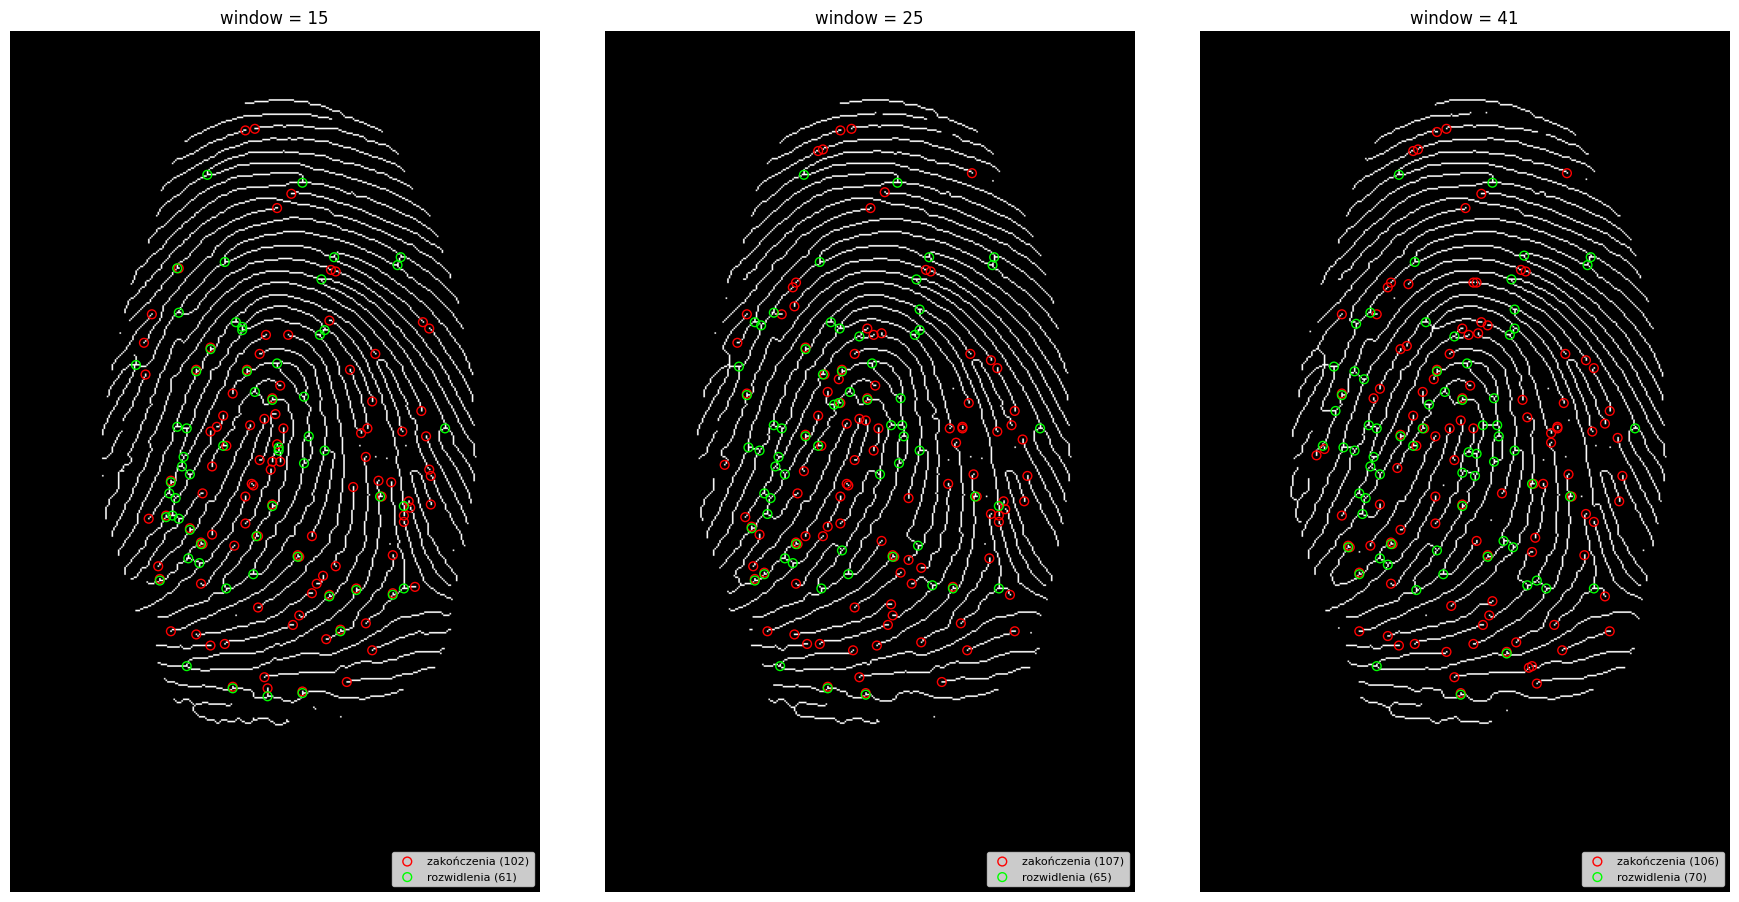

In [31]:
def run(gray, window=SAUVOLA_WINDOW, min_size=MIN_OBJECT_SIZE):
    smooth = filters.gaussian(gray, sigma=GAUSS_SIGMA)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply((smooth * 255).astype(np.uint8))
    blur = filters.gaussian(gray, sigma=10)
    roi = ndi.binary_erosion(ndi.binary_fill_holes(blur < filters.threshold_otsu(blur)), iterations=10)
    b = (clahe < filters.threshold_sauvola(clahe, window_size=window)) & roi
    b = morphology.remove_small_holes(morphology.remove_small_objects(b, max_size=min_size), max_size=min_size)
    sk = prune(morphology.skeletonize(b))
    e, f = find_minutiae(sk, roi)
    return sk, e, f

def compare(name, values):
    fig, ax = plt.subplots(1, len(values), figsize=(6 * len(values), 9))
    for a, v in zip(ax, values):
        sk, e, f = run(gray, **{name: v})
        show(a, sk, e, f, f"{name} = {v}")
        print(f"{name} = {v}: zakończenia = {len(e)}, rozwidlenia = {len(f)}")
    plt.tight_layout(); plt.show()

compare("window", [15, 25, 41])


**Wnioski (zad. 2):** Okno 15 daje 102 zakończenia i 61 rozwidleń, okno 25: 107 i 65, okno 41: 106 i 70. Małe okno (15 px, porównywalne z odstępem linii) daje cieńsze, częściej przerwane linie. Duże okno (41 px) daje grubsze linie, które w ciemnych miejscach zlewają się z sąsiednimi (mostki), dlatego rośnie liczba rozwidleń. Szkielet w środku odcisku jest dla wszystkich okien prawie taki sam; różnice są na brzegach i w miejscach o słabym kontraście.


min_size = 10: zakończenia = 105, rozwidlenia = 81
min_size = 22: zakończenia = 107, rozwidlenia = 65
min_size = 50: zakończenia = 105, rozwidlenia = 61


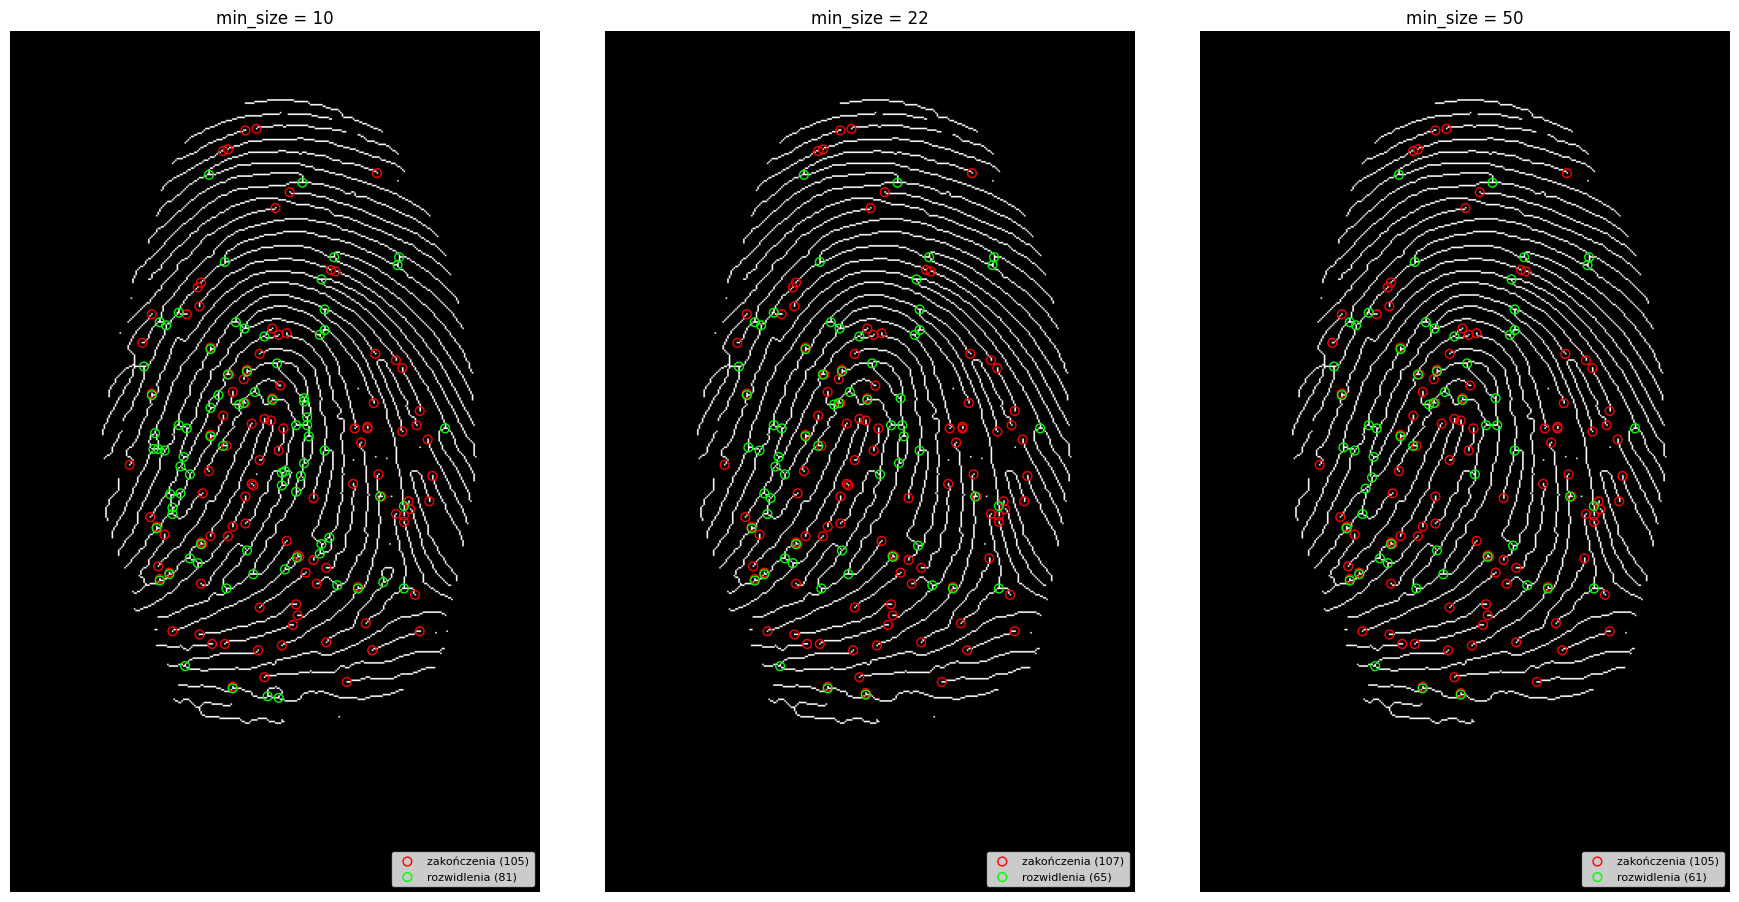

In [32]:
compare("min_size", [10, 22, 50])


**Wnioski (zad. 3):** `MIN_OBJECT_SIZE` = 10, 22, 50 daje odpowiednio 105, 107 i 105 zakończeń, więc liczba fałszywych zakończeń prawie się nie zmienia (drobne fragmenty i tak usuwa przycinanie szkieletu). Zmienia się za to liczba rozwidleń: 81 → 65 → 61. Przy małej wartości `remove_small_holes` nie zalewa porów w liniach, a każda dziurka w linii daje w szkielecie pętelkę, czyli dwa fałszywe rozwidlenia.


### Zadanie 4 – inny odcisk palca


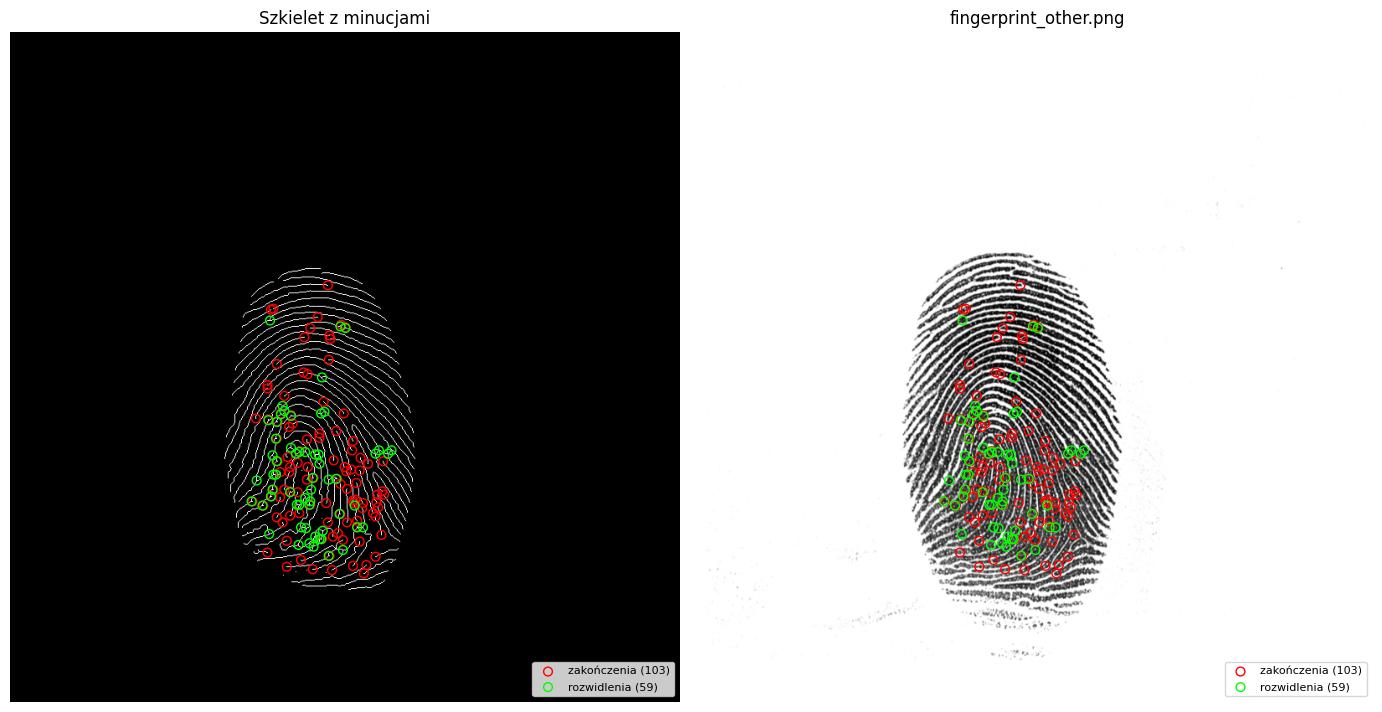

In [33]:
other = load_gray("fingerprint_other.png")
sk, e, f = run(other)
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
show(ax[0], sk, e, f, "Szkielet z minucjami")
show(ax[1], other, e, f, "fingerprint_other.png")
plt.tight_layout(); plt.show()


**Wnioski (zad. 4):** Na innym palcu (`fingerprint_other.png`) wykryto 103 zakończenia i 59 rozwidleń. Maska ROI z rozmytego obrazu dobrze odcina tło i zabrudzenia wokół odcisku. Minucje skupiają się jednak w ciemnym środku i na dole odcisku. Tam palec był mocno dociśnięty, doliny między liniami prawie znikają i linie się zlewają, co daje dużo fałszywych rozwidleń i zakończeń. Odcisk jest też mniejszy (gęstsze linie), więc parametry dobrane dla pierwszego obrazu są dla niego za duże. Algorytm działa dobrze tylko na wyraźnych obrazach o podobnej skali.


### Zadanie 5 – błędnie wykryte punkty


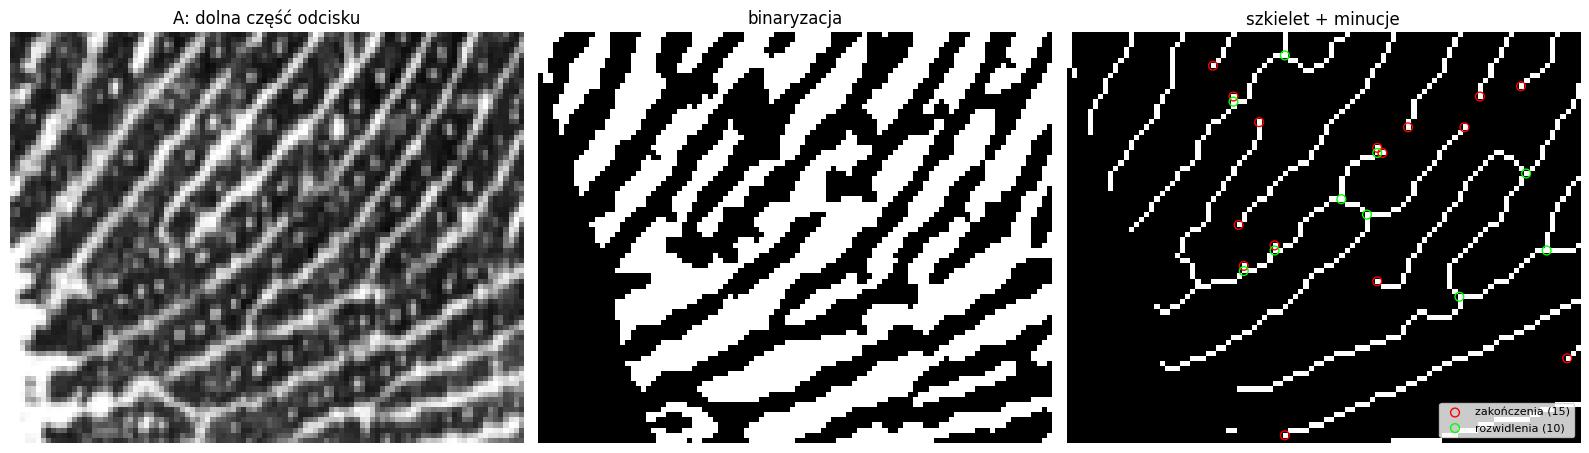

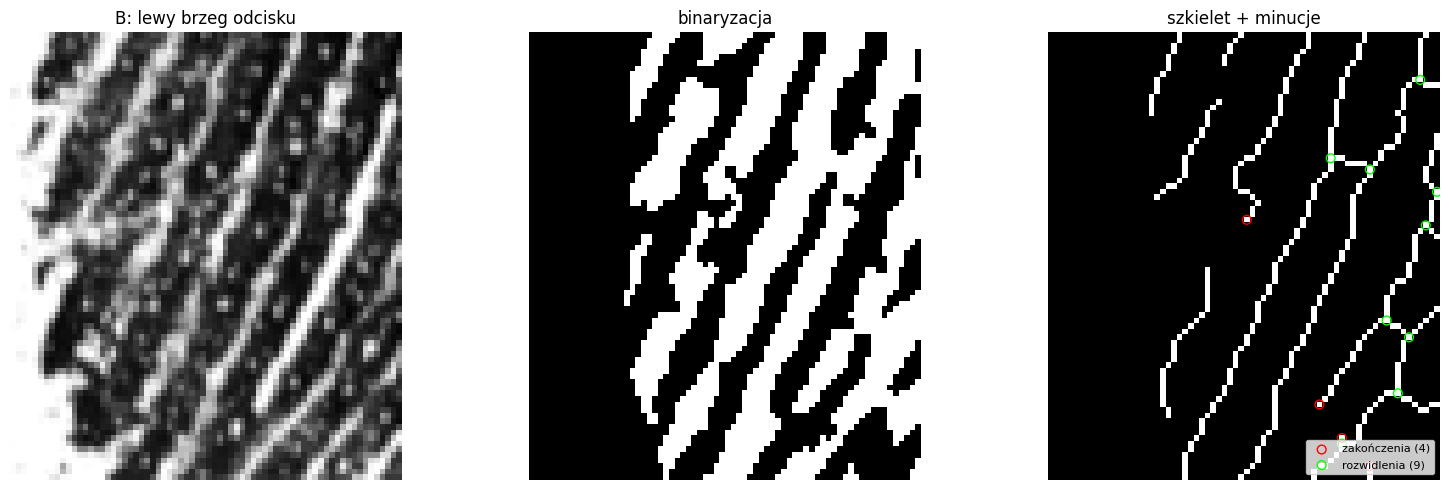

In [34]:
# dwa powiększone fragmenty odcisku
for (y0, y1, x0, x1), title in [((300, 380, 60, 160), "A: dolna część odcisku"),
                                ((240, 320, 40, 110), "B: lewy brzeg odcisku")]:
    inside = lambda pts: pts[(pts[:, 0] >= y0) & (pts[:, 0] < y1) & (pts[:, 1] >= x0) & (pts[:, 1] < x1)] - [y0, x0]
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    ax[0].imshow(gray[y0:y1, x0:x1], cmap='gray'); ax[0].set_title(title); ax[0].axis('off')
    ax[1].imshow(clean_img[y0:y1, x0:x1], cmap='gray'); ax[1].set_title("binaryzacja"); ax[1].axis('off')
    show(ax[2], pruned[y0:y1, x0:x1], inside(ends), inside(bifs), "szkielet + minucje")
    plt.tight_layout(); plt.show()


**Wnioski (zad. 5):** * **A – dolna część odcisku:** widać kilka miejsc, gdzie zakończenie i rozwidlenie leżą tuż obok siebie. To krótkie odgałęzienie szkieletu, które powstało z nierównego brzegu linii (np. przez por potowy) i nie zostało usunięte przez przycinanie. W rzeczywistości linia jest tam ciągła, bez minucji.
* **B – lewy brzeg odcisku:** palec był tu słabiej dociśnięty, a tusz rozmazany. Sąsiednie linie łączą się poziomymi mostkami, więc szkielet ma pary fałszywych **rozwidleń** (dwa zielone punkty na końcach mostka). Przerwane linie dają z kolei fałszywe **zakończenia**.

Mechanizm: każdy błąd binaryzacji (przerwa, mostek, dziura) zmienia kształt szkieletu, a Crossing Number patrzy tylko na 8 sąsiadów piksela, więc nie odróżni prawdziwej minucji od takiego błędu.


**Rozszerzenie zadania **– porównanie dwóch odcisków palców
To może być szczególnie interesujący element laboratorium.

Studenci otrzymują trzy obrazy:
- Obraz A – odcisk pierwszego palca.
- Obraz B – drugi odcisk tego samego palca.
- Obraz C – odcisk innego palca.
Ich zadaniem jest przeprowadzenie szkieletyzacji, wykrycie minucji i porównanie rozmieszczenia charakterystycznych punktów.

W tym wariancie należy uwzględnić również przesunięcie i obrót obrazów, ponieważ odciski tego samego palca nie muszą być identycznie ułożone.

# Zadanie dla chetnych. Analiza układu naczyń krwionośnych (lub dróg) z wykorzystaniem szkieletyzacji

Cel:
Zastosować szkieletyzację do analizy i modelowania rozgałęzionej struktury obiektów — takich jak naczynia krwionośne, korzenie roślin, sieci drogowe lub linie pisma.
Celem jest uzyskanie uproszczonej reprezentacji struktury (szkieletu), która zachowuje topologię, umożliwia pomiar długości i rozgałęzień.

Wyobraź sobie, że jesteś inżynierem biomedycznym analizującym zdjęcia mikroskopowe naczyń krwionośnych. Obraz jest binarny (ciemne naczynia na jasnym tle). Chcesz automatycznie:

* uzyskać szkielet naczyń,
* obliczyć łączną długość naczyń,
* określić liczbę rozgałęzień i końcówek.

Podobne podejście można wykorzystać np. w analizie:

* sieci dróg z obrazów satelitarnych,
* struktur roślinnych (korzeni, liści),
* połączeń ścieżek w układach scalonych.


# Kolejne kroki

Wczytaj obraz (np. mikroskopowy obraz naczyń lub sieć dróg — można użyć data.retina() lub własnego zdjęcia).
Jeśli obraz jest kolorowy — przekształć go do skali szarości.

1. Wykonaj progowanie (np. metodą Otsu), aby uzyskać obraz binarny przedstawiający strukturę obiektu.

2. Wyczyść obraz – usuń małe obiekty i zakłócenia (remove_small_objects, closing, opening).

3. Zastosuj szkieletyzację (skeletonize) do uzyskania osi struktur.

4. Oblicz cechy geometryczne:

* liczbę końcówek szkieletu (punkty z jednym sąsiadem),
* liczbę rozgałęzień (punkty z więcej niż dwoma sąsiadami).

Koncepcja cech geometrycznych szkieletu:
Każdy piksel w szkielecie ma pewną liczbę sąsiadów (8-sąsiedztwo):
* Końcówka (endpoint): piksel, który ma dokładnie jednego sąsiada.
→ Jest to koniec gałęzi szkieletu.
* Rozgałęzienie (branch point): piksel, który ma więcej niż dwóch sąsiadów.→ W tym miejscu łączą się lub rozdzielają gałęzie struktury.

Wizualizuj wynik:

* oryginalny obraz,
* obraz binarny,
* szkielet